In [23]:
from langgraph.graph import StateGraph, START, END
from langchain_groq import ChatGroq
from typing import TypedDict, Annotated, Literal
from dotenv import load_dotenv
from pydantic import BaseModel, Field
from langchain_core.messages import SystemMessage, HumanMessage
import operator
from langgraph.checkpoint.memory import InMemorySaver

In [39]:
load_dotenv()
model = ChatGroq(model="openai/gpt-oss-20b", max_tokens=1000)

In [25]:
class JokeSchema(TypedDict):
    topic:str
    joke:str
    explanation:str

In [26]:
def joke_gen(state:JokeSchema):
    prompt = f"Give me a joke in the topic - {state['topic']}"

    response = model.invoke(prompt).content

    return {'joke': response}

In [27]:
def joke_explain(state:JokeSchema):
    prompt = f"Give me the explanation of the joke  - {state['joke']}"

    response = model.invoke(prompt).content

    return {'explanation': response}

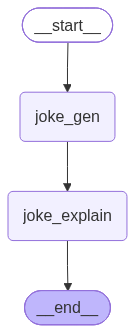

In [28]:
graph = StateGraph(JokeSchema)
graph.add_node('joke_gen', joke_gen)
graph.add_node('joke_explain', joke_explain)

graph.add_edge(START, 'joke_gen')
graph.add_edge('joke_gen', 'joke_explain')
graph.add_edge('joke_explain', END)


checkpointer = InMemorySaver()
workflow = graph.compile(checkpointer=checkpointer)
workflow

In [29]:
config1 = {"configurable": {"thread_id": "1"}}


In [32]:
initial_state = {
    'topic': 'pizza',
    
}
workflow.invoke(initial_state, config=config1)

{'topic': 'pizza',
 'joke': 'Why did the pizza start a band?\n\nBecause it had a *crust* of talent and wanted to *slice* into the charts! 🍕🎸',
 'explanation': '**Explanation**\n\nThe joke is a classic pun that mixes pizza‑related words with music‑industry slang:\n\n1. **“Crust of talent”**  \n   - *Crust* is the outer edge of a pizza.  \n   - In idiomatic English, “a crust of talent” sounds like “a core of talent,” implying the pizza is inherently talented. The word “crust” is used literally, making the phrase humorous.\n\n2. **“Slice into the charts”**  \n   - *Slice* is what you cut a pizza into.  \n   - In the music world, “to break into the charts” means to become popular or hit a high position on music charts. Replacing “break” with “slice” ties the pizza theme back to music, creating a playful double meaning.\n\n3. **Absurd premise**  \n   - The idea of a pizza forming a band is inherently ridiculous. The humor is amplified by the absurdity of a food item pursuing a career in mus

In [33]:
workflow.get_state(config=config1)

StateSnapshot(values={'topic': 'pizza', 'joke': 'Why did the pizza start a band?\n\nBecause it had a *crust* of talent and wanted to *slice* into the charts! 🍕🎸', 'explanation': '**Explanation**\n\nThe joke is a classic pun that mixes pizza‑related words with music‑industry slang:\n\n1. **“Crust of talent”**  \n   - *Crust* is the outer edge of a pizza.  \n   - In idiomatic English, “a crust of talent” sounds like “a core of talent,” implying the pizza is inherently talented. The word “crust” is used literally, making the phrase humorous.\n\n2. **“Slice into the charts”**  \n   - *Slice* is what you cut a pizza into.  \n   - In the music world, “to break into the charts” means to become popular or hit a high position on music charts. Replacing “break” with “slice” ties the pizza theme back to music, creating a playful double meaning.\n\n3. **Absurd premise**  \n   - The idea of a pizza forming a band is inherently ridiculous. The humor is amplified by the absurdity of a food item pursu

In [34]:
list(workflow.get_state_history(config=config1))

[StateSnapshot(values={'topic': 'pizza', 'joke': 'Why did the pizza start a band?\n\nBecause it had a *crust* of talent and wanted to *slice* into the charts! 🍕🎸', 'explanation': '**Explanation**\n\nThe joke is a classic pun that mixes pizza‑related words with music‑industry slang:\n\n1. **“Crust of talent”**  \n   - *Crust* is the outer edge of a pizza.  \n   - In idiomatic English, “a crust of talent” sounds like “a core of talent,” implying the pizza is inherently talented. The word “crust” is used literally, making the phrase humorous.\n\n2. **“Slice into the charts”**  \n   - *Slice* is what you cut a pizza into.  \n   - In the music world, “to break into the charts” means to become popular or hit a high position on music charts. Replacing “break” with “slice” ties the pizza theme back to music, creating a playful double meaning.\n\n3. **Absurd premise**  \n   - The idea of a pizza forming a band is inherently ridiculous. The humor is amplified by the absurdity of a food item purs

In [35]:
config2 = {"configurable": {"thread_id": "2"}}

In [40]:
initial_state = {
    'topic': 'pasta',
    
}
workflow.invoke(initial_state, config=config2)

{'topic': 'pasta',
 'joke': 'Why did the spaghetti break up with the lasagna?\n\nBecause it couldn’t handle all the *layered* drama— it just wanted a *simple* noodle relationship! 🍝😄',
 'explanation': '**Why the joke works**\n\n| Element | What it does | Why it’s funny |\n|---------|--------------|----------------|\n| **Anthropomorphizing food** | Spaghetti and lasagna are treated like people in a romantic relationship. | Turning inanimate dishes into lovers is absurd and immediately sets up a comedic scenario. |\n| **“Layered drama”** | A literal description of lasagna (it’s made of layers of pasta, sauce, cheese, etc.) + a metaphor for emotional drama. | The double meaning is a classic pun: “layered” is both physical and figurative. |\n| **“Simple noodle relationship”** | “Noodle” is a literal reference to spaghetti’s shape and also slang for a simple or goofy person. | The play on “simple” (easy, uncomplicated) and “noodle” (both the food and a light‑hearted insult) adds a second la

In [42]:
list(workflow.get_state(config=config2))

[{'topic': 'pasta',
  'joke': 'Why did the spaghetti break up with the lasagna?\n\nBecause it couldn’t handle all the *layered* drama— it just wanted a *simple* noodle relationship! 🍝😄',
  'explanation': '**Why the joke works**\n\n| Element | What it does | Why it’s funny |\n|---------|--------------|----------------|\n| **Anthropomorphizing food** | Spaghetti and lasagna are treated like people in a romantic relationship. | Turning inanimate dishes into lovers is absurd and immediately sets up a comedic scenario. |\n| **“Layered drama”** | A literal description of lasagna (it’s made of layers of pasta, sauce, cheese, etc.) + a metaphor for emotional drama. | The double meaning is a classic pun: “layered” is both physical and figurative. |\n| **“Simple noodle relationship”** | “Noodle” is a literal reference to spaghetti’s shape and also slang for a simple or goofy person. | The play on “simple” (easy, uncomplicated) and “noodle” (both the food and a light‑hearted insult) adds a second

In [43]:
list(workflow.get_state_history(config=config2))

[StateSnapshot(values={'topic': 'pasta', 'joke': 'Why did the spaghetti break up with the lasagna?\n\nBecause it couldn’t handle all the *layered* drama— it just wanted a *simple* noodle relationship! 🍝😄', 'explanation': '**Why the joke works**\n\n| Element | What it does | Why it’s funny |\n|---------|--------------|----------------|\n| **Anthropomorphizing food** | Spaghetti and lasagna are treated like people in a romantic relationship. | Turning inanimate dishes into lovers is absurd and immediately sets up a comedic scenario. |\n| **“Layered drama”** | A literal description of lasagna (it’s made of layers of pasta, sauce, cheese, etc.) + a metaphor for emotional drama. | The double meaning is a classic pun: “layered” is both physical and figurative. |\n| **“Simple noodle relationship”** | “Noodle” is a literal reference to spaghetti’s shape and also slang for a simple or goofy person. | The play on “simple” (easy, uncomplicated) and “noodle” (both the food and a light‑hearted insu